# Cylindrical and spherical coordinates

`convert_coordinates(mesh, system, axis=..., arrays=[...])` records each point's `(r, θ, z)` (or spherical `(r, θ, φ)`) about an axis as point data, and rewrites named vector and tensor fields in the local basis of each point: the radial, tangential and axial components a rotating machine or a pressure vessel is read in. The points do not move, and `inverse=True` turns the components back into Cartesian ones. See `doc/coordinates.md`.

In [1]:
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def draw_surface(ax, points, tris, values, title, cmap='coolwarm', view=(20, 35)):
    """A triangle surface coloured by a point field: PyVista's render embedded
    as an image when GL is available, else a matplotlib Poly3DCollection."""
    if pv is not None:
        faces = np.hstack([np.full((len(tris), 1), 3), tris]).ravel()
        grid = pv.PolyData(points, faces)
        grid.point_data['f'] = values
        pl = pv.Plotter(off_screen=True, window_size=(700, 600))
        pl.add_mesh(grid, scalars='f', cmap=cmap, smooth_shading=True)
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
        ax.axis('off')
    else:
        norm = plt.Normalize(np.nanmin(values), np.nanmax(values))
        coll = Poly3DCollection(points[tris], facecolors=plt.get_cmap(cmap)(norm(values[tris].mean(axis=1))),
                                edgecolor='none')
        ax.add_collection3d(coll)
        lim = np.abs(points).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(*view)
        ax.set_axis_off()
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6)
    ax.set_title(title)

No GL available: rendering with matplotlib.


## A rotor: swirl and through-flow

The velocity of a rigidly spinning rotor with an axial through-flow, `u = ω × x + w e_z`, is a tangle of `x` and `y` components in Cartesian form. In cylindrical components it is `(0, ω r, w)`: no radial flow, a swirl growing linearly with the radius, and a constant axial velocity.

{'num_arrays': 1, 'num_singular': 0}
max |u_r| = 2.2e-16; u_theta / r = 3.000000 (omega = 3.0); u_z = 0.500


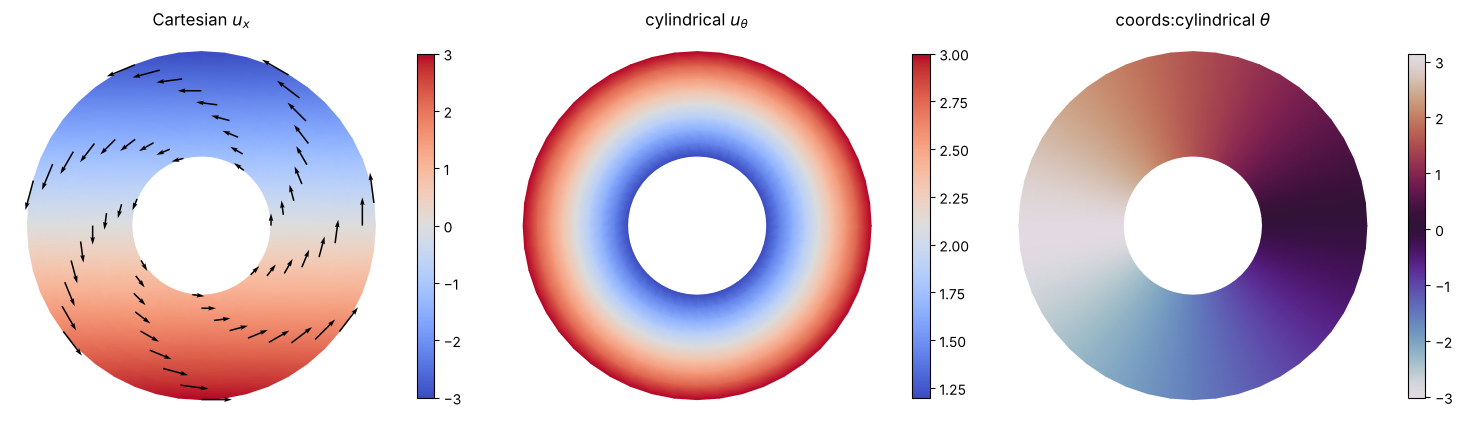

In [2]:
rotor = mp.annulus(inner_radius=0.4, outer_radius=1.0, ntheta=48, nr=8, cell_type='triangle')
omega, w = 3.0, 0.5
x, y = rotor.points[:, 0], rotor.points[:, 1]
rotor.point_data['U'] = np.column_stack([-omega * y, omega * x, np.full(len(x), w)])

cyl, report = mp.convert_coordinates(rotor, 'cylindrical', axis=(0, 0, 1), arrays=['U'], return_report=True)
print(report)
r, theta, z = cyl.point_data['coords:cylindrical'].T
u_r, u_t, u_z = cyl.point_data['U'].T
print(f'max |u_r| = {np.abs(u_r).max():.1e}; u_theta / r = {np.mean(u_t / r):.6f} (omega = {omega}); u_z = {u_z.mean():.3f}')

tris = rotor.cells_dict['triangle']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, values, title in ((axes[0], rotor.point_data['U'][:, 0], 'Cartesian $u_x$'),
                          (axes[1], u_t, r'cylindrical $u_\theta$'),
                          (axes[2], theta, r'coords:cylindrical $\theta$')):
    tc = ax.tripcolor(x, y, tris, values, shading='gouraud', cmap='coolwarm' if ax is not axes[2] else 'twilight')
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title)
    plt.colorbar(tc, ax=ax, shrink=0.8)
step = slice(None, None, 7)
axes[0].quiver(x[step], y[step], rotor.point_data['U'][step, 0], rotor.point_data['U'][step, 1], color='k', width=0.004)
plt.tight_layout()
plt.show()

## A thick-walled pipe under pressure

Lamé's solution for a pipe of radii `a < b` under internal pressure `p` has `σ_rr = A − B / r²` and the hoop stress `σ_θθ = A + B / r²`, with no shear in cylindrical components. Written as a Cartesian tensor field over a hexahedral pipe, `σ_xx` mixes the two; `convert_coordinates` takes it apart again, and the round trip with `inverse=True` recovers the input.

max |shear| in cylindrical components: 2.2e-15
hoop stress error: 7.1e-15
round-trip error: 7.1e-15


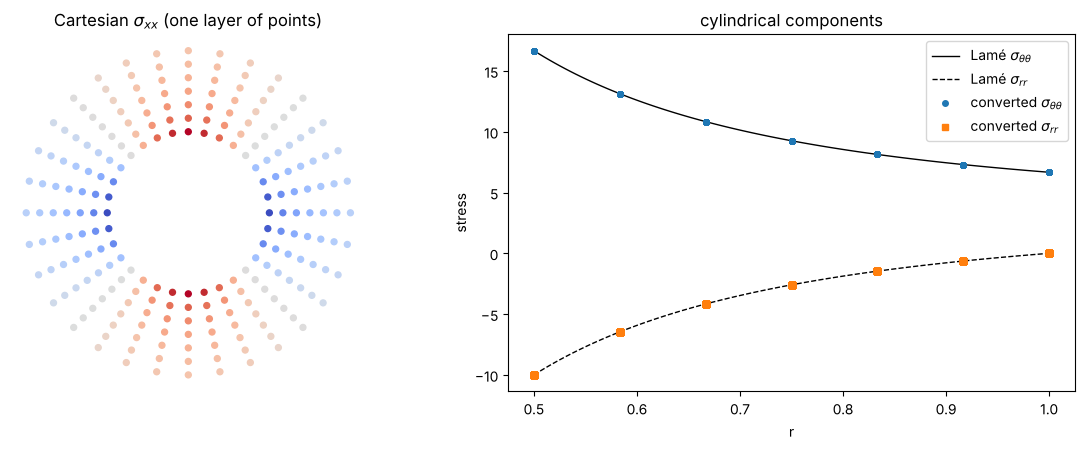

In [3]:
a, b, p = 0.5, 1.0, 10.0
pipe = mp.pipe(inner_radius=a, outer_radius=b, height=0.5, ntheta=32, nr=6, nz=2)
A, B = p * a**2 / (b**2 - a**2), p * a**2 * b**2 / (b**2 - a**2)
xy = pipe.points[:, :2]
rr = np.linalg.norm(xy, axis=1)
c, s = xy[:, 0] / rr, xy[:, 1] / rr
srr, stt = A - B / rr**2, A + B / rr**2
sigma = np.zeros((len(rr), 3, 3))
sigma[:, 0, 0] = srr * c**2 + stt * s**2
sigma[:, 1, 1] = srr * s**2 + stt * c**2
sigma[:, 0, 1] = sigma[:, 1, 0] = (srr - stt) * c * s
sigma[:, 2, 2] = 2 * 0.3 * A  # plane strain, Poisson's ratio 0.3
pipe.point_data['sigma'] = sigma.reshape(-1, 9)

local = mp.convert_coordinates(pipe, 'cylindrical', arrays=['sigma'])
S = local.point_data['sigma'].reshape(-1, 3, 3)
print(f'max |shear| in cylindrical components: {np.abs(S[:, 0, 1]).max():.1e}')
print(f'hoop stress error: {np.abs(S[:, 1, 1] - stt).max():.1e}')
back = mp.convert_coordinates(local, 'cylindrical', arrays=['sigma'], inverse=True, record_coordinates=False)
print(f'round-trip error: {np.abs(back.point_data["sigma"] - pipe.point_data["sigma"]).max():.1e}')

r_plot = np.linspace(a, b, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
bottom = np.abs(pipe.points[:, 2]) < 1e-12
axes[0].scatter(xy[bottom, 0], xy[bottom, 1], c=sigma[bottom, 0, 0], cmap='coolwarm', s=18)
axes[0].set_aspect('equal'); axes[0].axis('off'); axes[0].set_title(r'Cartesian $\sigma_{xx}$ (one layer of points)')
axes[1].plot(r_plot, A + B / r_plot**2, 'k-', lw=1, label=r'Lamé $\sigma_{\theta\theta}$')
axes[1].plot(r_plot, A - B / r_plot**2, 'k--', lw=1, label=r'Lamé $\sigma_{rr}$')
axes[1].plot(rr, S[:, 1, 1], 'o', ms=4, label=r'converted $\sigma_{\theta\theta}$')
axes[1].plot(rr, S[:, 0, 0], 's', ms=4, label=r'converted $\sigma_{rr}$')
axes[1].set_xlabel('r'); axes[1].set_ylabel('stress'); axes[1].legend(); axes[1].set_title('cylindrical components')
plt.tight_layout()
plt.show()

## A sphere: spherical components

In spherical components the outward normal of a sphere about its centre is `(1, 0, 0)` everywhere, and the recorded coordinates are the radius, the polar angle from the axis and the azimuth about it. The two poles lie on the axis, where the azimuth is undefined: they are counted in `num_singular`.

{'num_arrays': 1, 'num_singular': 2}
normal in spherical components, max deviation from (1, 0, 0): 2.7755575615628914e-16


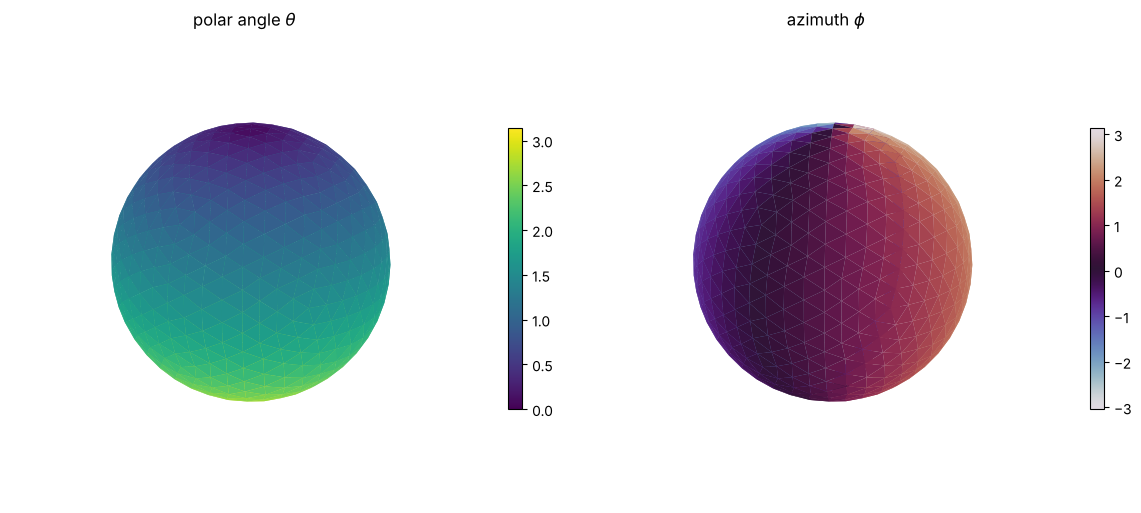

In [4]:
sphere = mp.icosa_sphere(subdivisions=3)
sphere = mp.Mesh(sphere.points / np.linalg.norm(sphere.points, axis=1)[:, None], sphere.cells)
sphere.point_data['n'] = sphere.points.copy()
out, report = mp.convert_coordinates(sphere, 'spherical', axis=(0, 0, 1), arrays=['n'], return_report=True)
print(report)
print('normal in spherical components, max deviation from (1, 0, 0):',
      np.abs(out.point_data['n'] - [1.0, 0.0, 0.0]).max())
r_s, polar, azimuth = out.point_data['coords:spherical'].T

tris = sphere.cells_dict['triangle']
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection=None if pv else '3d')
draw_surface(ax, sphere.points, tris, polar, r'polar angle $\theta$', cmap='viridis')
ax = fig.add_subplot(1, 2, 2, projection=None if pv else '3d')
draw_surface(ax, sphere.points, tris, azimuth, r'azimuth $\phi$', cmap='twilight')
plt.tight_layout()
plt.show()

## In a pipeline, and on the command line

The step is `ConvertCoordinates` in a settings pipeline, and the `coordinates` verb in both CLIs.

In [5]:
spun, rep = mp.apply_operations(rotor, [
    {"Op": "ConvertCoordinates", "System": "cylindrical", "Arrays": ["U"]},
])
print(rep['steps'][0])
print('meshioplusplus coordinates rotor.vtu rotor_cyl.vtu --arrays U --json')

{'op': 'ConvertCoordinates', 'NumArrays': 1.0, 'NumSingular': 0.0}
meshioplusplus coordinates rotor.vtu rotor_cyl.vtu --arrays U --json
